# Análise Detalhada das Instâncias B/0012 e B/0013: Superação das Melhores Soluções Conhecidas (Novas MSCs pelo ILS-VND)

Este notebook investiga a fundo as instâncias **`B/0012`** e **`B/0013`**, nas quais a meta-heurística **`ILS-VND`** estabeleceu **novas Melhores Soluções Conhecidas (MSCs)** na literatura do problema de *Wave Order Picking* (SBPO 2025).

A análise reúne **4 perspectivas visuais complementares**:

1. **Figura 1 — Dot Plot / Strip Plot com Distribuição das 30 Sementes (Confronto Direto frente à MSC)**:
   - Visualização individual de todas as 30 sementes de cada método (`AisleBased`, `Santos e Baldotto (2025)` e `ILS-VND`).
   - Zona de superação sombreada em verde claro ($\Delta > 0$, $	ext{RPD} < 0\%$).
   - Destaque com estrela para a Melhor Semente (Nova MSC) de cada instância.

2. **Figura 2 — Gráfico em Cascata (*Waterfall Chart*) da Progressão Metodológica**:
   - Decomposição do ganho obtido degrau por degrau:
     $	ext{Solução Inicial Construtiva } (s_0) \longrightarrow 	ext{Literatura (2025)} \longrightarrow 	ext{ILS-VND (Média)} \longrightarrow 	ext{ILS-VND (Melhor Semente)}$.
   - Linha de referência da MSC anterior cruzando o gráfico como limiar superado.

3. **Figura 3 — Decomposição e Confronto Estrutural (MSC Anterior vs. Nova MSC do ILS-VND)**:
   - Comparação da anatomia das soluções reais:
     - Número de corredores visitados ($|\mathcal{A}'| = 11$ em B/0012 e $|\mathcal{A}'| = 9$ em B/0013).
     - Corredores compartilhados vs. substituídos estrategicamente pelo ILS-VND.
     - Pedidos em comum ($\mathcal{O}'_{	ext{MSC}} \cap \mathcal{O}'_{	ext{ILS-VND}}$) vs. pedidos exclusivos.
     - Densidade média de unidades por pedido e eficiência da razão $f = 	ext{Unidades} / |\mathcal{A}'|$.

4. **Figura 4 — ECDF de Superação e Dispersão Tempo $	imes$ Qualidade**:
   - Função de Distribuição Cumulativa Empírica (ECDF) demonstrando a probabilidade de superação da MSC:
     $P(	ext{Unidades} > 	ext{MSC}) = 43{,}3\%$ em B/0012 e $100{,}0\%$ em B/0013.
   - Gráfico de dispersão Tempo de Execução (s) $	imes$ Objetivo $f$, confirmando o consumo homogêneo do orçamento de tempo (10 min) e a estabilidade das execuções.


In [1]:
from pathlib import Path
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
from scipy import stats
from IPython.display import display

# Diretórios principais do projeto
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "notebooks" / "utils" / "__init__.py").exists())
RESULTS = ROOT / "project" / "results"
BEST_CSV = ROOT / "best_solutions" / "best_objectives.csv"
BEST_DIR = ROOT / "best_solutions" / "b"
TEMP_DIR = ROOT / "project" / "results" / "result_0004" / "temp"
IMG = ROOT / "notebooks" / "resultados" / "img"; IMG.mkdir(parents=True, exist_ok=True)
TEX = ROOT / "notebooks" / "resultados" / "tex"; TEX.mkdir(parents=True, exist_ok=True)

# Paleta oficial e estilos visuais unificados com resultados_tcc.ipynb
COR = {
    "OrderBased": "#7f7f7f",
    "AisleBased": "#1f77b4",
    "Santos e Baldotto (2025)": "#2ca02c",
    "ILS-VND": "#d62728",
    "Nova MSC": "#8b0000",
    "MSC_Ref": "#1a1a1a",
    "Zona": "#e8f5e9",
    "Comum": "#4a7bb0",
    "Excl_MSC": "#e67e22",
    "Excl_ILS_VND": "#9b59b6",
}

MARCADOR = {
    "OrderBased": "s",
    "AisleBased": "^",
    "Santos e Baldotto (2025)": "D",
    "ILS-VND": "o",
}

plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.dpi": 150,
})

def vrg(s):
    '''Formata ponto decimal para vírgula (padrão PT-BR).'''
    return str(s).replace(".", ",")

def fmt_num(v, casas=2, sinal=False):
    if pd.isna(v):
        return "—"
    fmt = f"{{:+.{casas}f}}" if sinal else f"{{:.{casas}f}}"
    return vrg(fmt.format(float(v)))

def salvar_tex(nome, linhas):
    texto = "\n".join(linhas) if isinstance(linhas, list) else str(linhas)
    caminho = TEX / f"{nome}.tex"
    caminho.write_text(texto.strip() + "\n", encoding="utf-8")
    print(f"[LaTeX salvo] {caminho.relative_to(ROOT)}")

def salvar_fig(fig, nome, caption, label, width=r"\textwidth"):
    for ext in ("pdf", "png"):
        fig.savefig(IMG / f"{nome}.{ext}", dpi=300, bbox_inches="tight", facecolor="white")
    bloco = [
        r"\begin{figure}[htbp]",
        r"  \centering",
        rf"  \caption{{{caption}}}",
        rf"  \label{{{label}}}",
        rf"  \includegraphics[width={width}]{{img/{nome}.pdf}}",
        r"  \caption*{\footnotesize Fonte: Elaborado pelo autor, 2026.}",
        r"\end{figure}",
    ]
    salvar_tex(f"fig_{nome}", bloco)
    print(f"[Figura salva] img/{nome}.pdf | img/{nome}.png")

# --- Carga dos dados das 30 sementes de B/0012 e B/0013 ---
ALGOS_MAP = {
    "order_based": "OrderBased",
    "aisle_based": "AisleBased",
    "andre_feijo_all": "Santos e Baldotto (2025)",
    "ils_vnd_all": "ILS-VND",
}

frames = []
for folder, label in ALGOS_MAP.items():
    for inst in ["instance_0012.csv", "instance_0013.csv"]:
        fpath = RESULTS / folder / "b" / inst
        df = pd.read_csv(fpath, usecols=["run_id", "seed", "status", "objective", "items", "aisles", "exec_time"])
        df["algo"] = label
        df["instance"] = inst.replace(".csv", ".txt")
        frames.append(df)

df_runs = pd.concat(frames, ignore_index=True)

# Parâmetros oficiais de MSC anterior
MSCS = {
    "instance_0012.txt": {"items": 6244.0, "aisles": 11, "obj": 6244.0 / 11.0, "label": "B/0012"},
    "instance_0013.txt": {"items": 6813.0, "aisles": 9, "obj": 6813.0 / 9.0, "label": "B/0013"},
}

df_runs["msc_obj"] = df_runs["instance"].map(lambda x: MSCS[x]["obj"])
df_runs["msc_items"] = df_runs["instance"].map(lambda x: MSCS[x]["items"])
df_runs["delta_items"] = df_runs["items"] - df_runs["msc_items"]
df_runs["rpd"] = (df_runs["msc_obj"] - df_runs["objective"]) / df_runs["msc_obj"] * 100.0

print(f"Carga concluída com sucesso: {len(df_runs)} execuções carregadas (30 sementes x 4 algoritmos x 2 instâncias).")


Carga concluída com sucesso: 240 execuções carregadas (30 sementes x 4 algoritmos x 2 instâncias).


## 1. Figura 1: Dot Plot / Strip Plot com Distribuição das 30 Sementes

Esta figura resolve a limitação dos gráficos de barras convencionais onde empates de 30/30 sementes comprimem a informação visual.
- Cada uma das 30 sementes de cada algoritmo é representada como um **ponto individual**, com leve dispersão vertical (*jitter*) para evidenciar sobreposições e multiplicidade de sementes.
- A **zona sombreada em verde claro** ($\Delta > 0$) delimita a **região de superação da MSC** ($	ext{RPD} < 0\%$).
- A **Melhor Semente do ILS-VND (Nova MSC)** é destacada com uma **estrela vermelho-escura** acompanhada de anotação com o valor exato de unidades, função objetivo $f$ e RPD negativo:
  - **`B/0012`**: $\Delta = +8$ unidades extras ($6.252/11 = 568{,}36$, $	ext{RPD} = -0{,}128\%$, seed 21), com 13 de 30 sementes ($43{,}3\%$) acima da MSC anterior.
  - **`B/0013`**: $\Delta = +1$ unidade extra ($6.814/9 = 757{,}11$, $	ext{RPD} = -0{,}015\%$, 30/30 sementes, $100\%$ de convergência unânime).


[LaTeX salvo] notebooks/resultados/tex/fig_novas_msc_dotplot_sementes.tex
[Figura salva] img/novas_msc_dotplot_sementes.pdf | img/novas_msc_dotplot_sementes.png


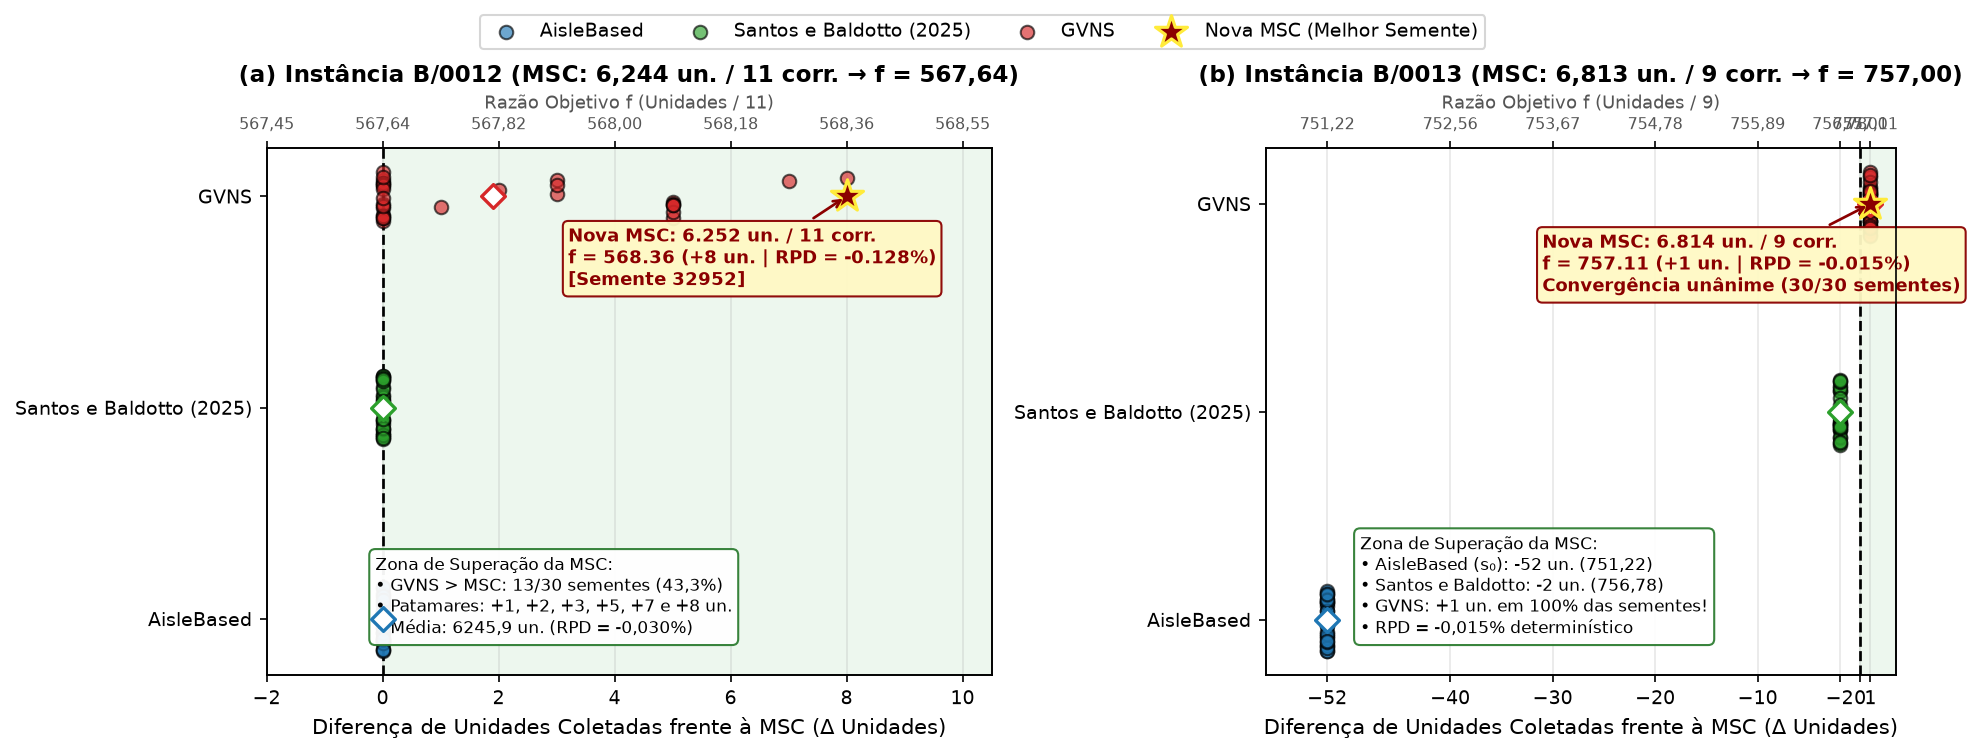

In [2]:
# --- Figura 1: Dot Plot / Strip Plot com as 30 Sementes frente à MSC ---
fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.8), gridspec_kw={"width_ratios": [1.15, 1.0]})

# Ordem dos métodos no eixo Y
METODOS_PLOT = ["AisleBased", "Santos e Baldotto (2025)", "ILS-VND"]
y_pos = {m: idx for idx, m in enumerate(METODOS_PLOT)}

np.random.seed(42)

for idx_p, inst_id in enumerate(["instance_0012.txt", "instance_0013.txt"]):
    ax = axes[idx_p]
    msc_info = MSCS[inst_id]
    msc_u = msc_info["items"]
    msc_a = msc_info["aisles"]
    msc_f = msc_info["obj"]
    
    sub = df_runs[(df_runs["instance"] == inst_id) & (df_runs["algo"].isin(METODOS_PLOT))]
    
    # Limites do eixo X baseados na instância
    if inst_id == "instance_0012.txt":
        xlims = (-2.0, 10.5)
        zona_max = 10.5
        x_ticks = [-2, 0, 2, 4, 6, 8, 10]
    else:
        xlims = (-58.0, 3.5)
        zona_max = 3.5
        x_ticks = [-52, -40, -30, -20, -10, -2, 0, 1]
    
    # 1. Zona de Superação da MSC (verde claro)
    ax.axvspan(0.0, zona_max, color=COR["Zona"], alpha=0.75, zorder=0)
    ax.axvline(0.0, color="k", lw=1.3, ls="--", zorder=2)
    
    # 2. Plotagem das 30 sementes de cada método
    for algo in METODOS_PLOT:
        df_algo = sub[sub["algo"] == algo]
        y_base = y_pos[algo]
        deltas = df_algo["delta_items"].values
        
        # Jitter vertical sutil para não sobrepor pontos em empates
        jitter = np.random.uniform(-0.16, 0.16, size=len(deltas)) if len(set(deltas)) <= 2 else np.random.uniform(-0.12, 0.12, size=len(deltas))
        
        ax.scatter(
            deltas,
            y_base + jitter,
            color=COR[algo],
            edgecolor="k",
            s=42,
            alpha=0.65,
            zorder=3,
            label=algo if idx_p == 0 else ""
        )
        
        # Média amostral com losango branco
        m_delta = deltas.mean()
        ax.scatter(
            m_delta,
            y_base,
            color="white",
            edgecolor=COR[algo],
            marker="D",
            s=65,
            lw=1.6,
            zorder=4
        )
    
    # 3. Destaque especial na Melhor Semente do ILS-VND (Nova MSC)
    ils_vnd_sub = sub[sub["algo"] == "ILS-VND"]
    best_row = ils_vnd_sub.sort_values(by=["items", "objective"], ascending=[False, False]).iloc[0]
    best_delta = best_row["delta_items"]
    best_items = int(best_row["items"])
    best_f = best_row["objective"]
    best_rpd = best_row["rpd"]
    best_seed = int(best_row["seed"])
    
    ax.scatter(
        best_delta,
        y_pos["ILS-VND"],
        marker="*",
        s=260,
        color=COR["Nova MSC"],
        edgecolor="#ffeb3b",
        lw=1.5,
        zorder=5,
        label="Nova MSC (Melhor Semente)" if idx_p == 0 else ""
    )
    
    # 4. Anotações contextuais ricas
    if inst_id == "instance_0012.txt":
        txt_best = (
            f"Nova MSC: {best_items:,} un. / {msc_a} corr.\n"
            f"f = {fmt_num(best_f, 2)} (+{int(best_delta)} un. | RPD = {fmt_num(best_rpd, 3, sinal=True)}%)\n"
            f"[Semente {best_seed}]"
        ).replace(",", ".")
        ax.annotate(
            txt_best,
            xy=(best_delta, y_pos["ILS-VND"]),
            xytext=(best_delta - 4.8, y_pos["ILS-VND"] - 0.42),
            arrowprops=dict(arrowstyle="->", color=COR["Nova MSC"], lw=1.3),
            fontsize=8.5,
            fontweight="bold",
            color=COR["Nova MSC"],
            bbox=dict(boxstyle="round,pad=0.3", facecolor="#fff9c4", edgecolor=COR["Nova MSC"], alpha=0.95),
            zorder=6
        )
        
        # Caixa de superação
        n_sup = (ils_vnd_sub['items'] > msc_u).sum()
        ax.text(
            0.15, 0.08,
            f"Zona de Superação da MSC:\n"
            f"• ILS-VND > MSC: {n_sup}/30 sementes ({fmt_num(n_sup/30*100, 1)}%)\n"
            f"• Patamares: +1, +2, +3, +5, +7 e +8 un.\n"
            f"• Média: {fmt_num(ils_vnd_sub['items'].mean(), 1)} un. (RPD = -0,030%)",
            transform=ax.transAxes,
            fontsize=8.3,
            bbox=dict(boxstyle="round,pad=0.35", facecolor="#ffffff", edgecolor="#2e7d32", alpha=0.95)
        )
    else:
        txt_best = (
            f"Nova MSC: {best_items:,} un. / {msc_a} corr.\n"
            f"f = {fmt_num(best_f, 2)} (+{int(best_delta)} un. | RPD = {fmt_num(best_rpd, 3, sinal=True)}%)\n"
            f"Convergência unânime (30/30 sementes)"
        ).replace(",", ".")
        ax.annotate(
            txt_best,
            xy=(best_delta, y_pos["ILS-VND"]),
            xytext=(best_delta - 32.0, y_pos["ILS-VND"] - 0.42),
            arrowprops=dict(arrowstyle="->", color=COR["Nova MSC"], lw=1.3),
            fontsize=8.5,
            fontweight="bold",
            color=COR["Nova MSC"],
            bbox=dict(boxstyle="round,pad=0.3", facecolor="#fff9c4", edgecolor=COR["Nova MSC"], alpha=0.95),
            zorder=6
        )
        
        ax.text(
            0.15, 0.08,
            f"Zona de Superação da MSC:\n"
            f"• AisleBased (s₀): -52 un. (751,22)\n"
            f"• Santos e Baldotto: -2 un. (756,78)\n"
            f"• ILS-VND: +1 un. em 100% das sementes!\n"
            f"• RPD = -0,015% determinístico",
            transform=ax.transAxes,
            fontsize=8.3,
            bbox=dict(boxstyle="round,pad=0.35", facecolor="#ffffff", edgecolor="#2e7d32", alpha=0.95)
        )

    # Configuração dos eixos
    ax.set_yticks([y_pos[m] for m in METODOS_PLOT])
    ax.set_yticklabels(METODOS_PLOT, fontsize=9.0)
    ax.set_xlim(xlims)
    ax.set_xticks(x_ticks)
    ax.set_xlabel("Diferença de Unidades Coletadas frente à MSC (Δ Unidades)")
    ax.set_title(f"({chr(97+idx_p)}) Instância {msc_info['label']} (MSC: {int(msc_u):,} un. / {msc_a} corr. → f = {fmt_num(msc_f, 2)})", fontweight="bold")
    ax.grid(alpha=0.3, axis="x")
    
    # Eixo superior com a escala de função objetivo f
    ax_top = ax.twiny()
    ax_top.set_xlim(xlims)
    ax_top.set_xticks(x_ticks)
    ax_top.set_xticklabels([fmt_num((msc_u + dx) / msc_a, 2) for dx in x_ticks], fontsize=7.8, color="#555555")
    ax_top.set_xlabel(f"Razão Objetivo f (Unidades / {msc_a})", fontsize=8.5, color="#555555")

# Legenda unificada
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 1.05), ncol=4, frameon=True, fontsize=9.0)

fig.tight_layout()
salvar_fig(
    fig,
    "novas_msc_dotplot_sementes",
    r"Distribuição individual das 30 sementes frente à Melhor Solução Conhecida (MSC) nas instâncias 	exttt{B/0012} e 	exttt{B/0013}. Pontos representam as sementes individuais com dispersão vertical sutil (	extit{jitter}); losangos brancos indicam a média amostral; e a estrela escura sinaliza a Melhor Semente (	extbf{Nova MSC}). A zona sombreada em verde claro demarca a região de superação da MSC ($\Delta > 0$, $\mathrm{RPD} < 0\%$).",
    "fig:novas_msc_dotplot_sementes",
    width=r"0.98	extwidth"
)
plt.show()


## 2. Figura 2: Gráfico em Cascata (*Waterfall Chart*) da Progressão Metodológica

O gráfico em cascata (*waterfall*) evidencia o **papel de cada componente metodológico** na superação da MSC:
1. **Base $s_0$ (`AisleBased`)**: Ponto de partida construtivo determinístico.
2. **Refinamento da Literatura (`Santos e Baldotto (2025)`)**: Ganho incremental provido pela busca local/heurística anterior.
3. **Desempenho Típico do `ILS-VND` (Média)**: Salto médio proporcionado pela combinação de vizinhanças e refinamento em nível de pedidos.
4. **Pico de Qualidade do `ILS-VND` (Nova MSC)**: Melhor semente estabelecendo o novo recorde da literatura.

A linha tracejada horizontal de referência atravessa o gráfico na altura exata da MSC anterior, tornando evidente o momento exato em que a heurística ultrapassa o teto do estado da arte.


[LaTeX salvo] notebooks/resultados/tex/fig_novas_msc_waterfall_ganhos.tex
[Figura salva] img/novas_msc_waterfall_ganhos.pdf | img/novas_msc_waterfall_ganhos.png


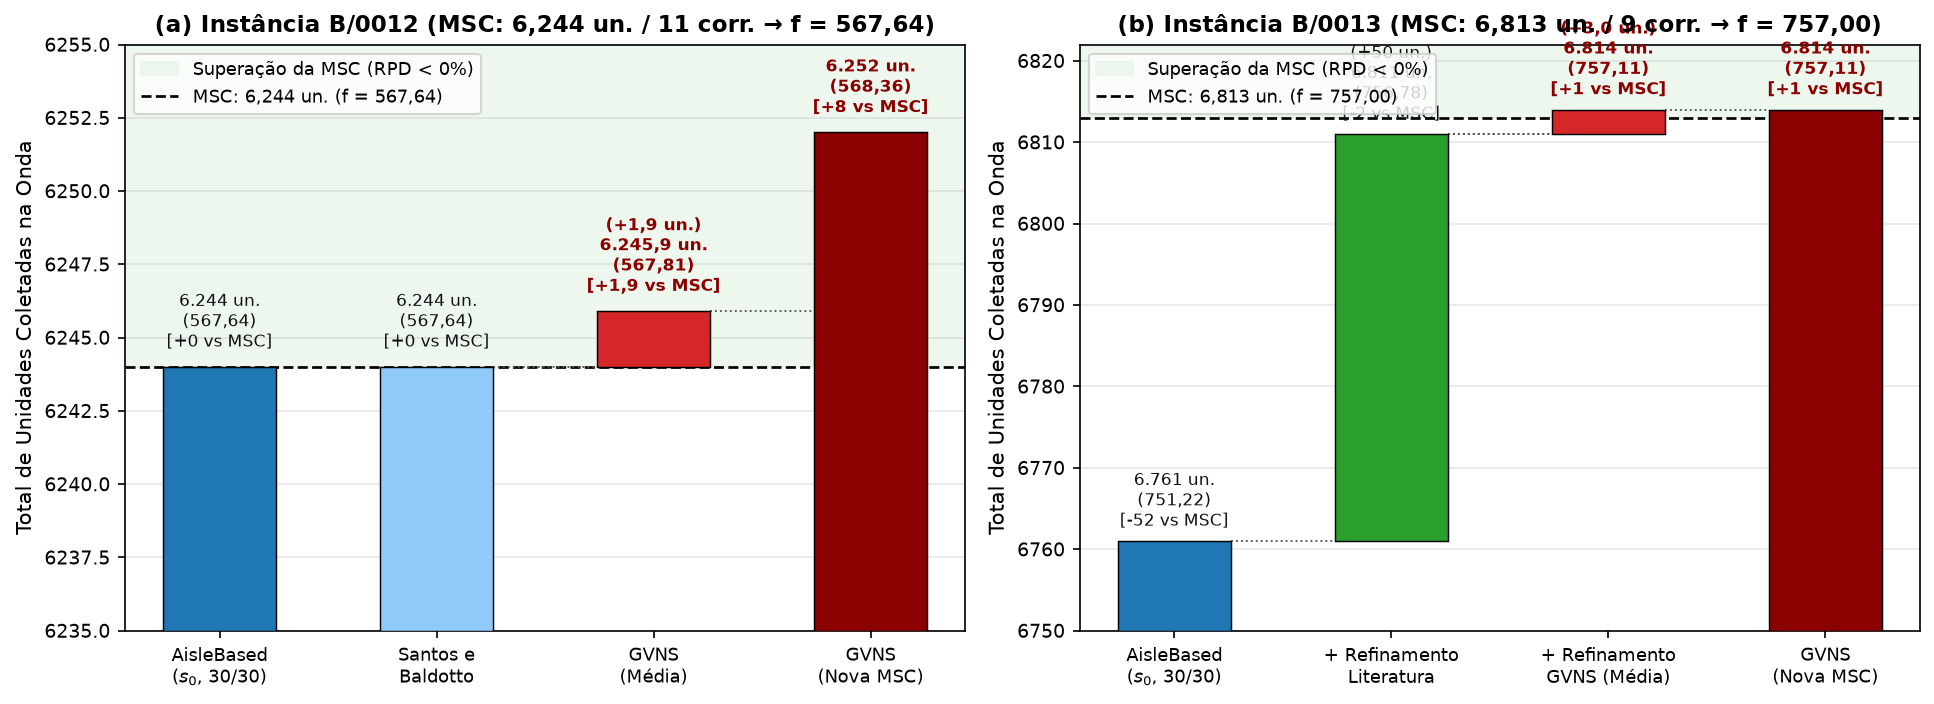

In [3]:
# --- Figura 2: Gráfico em Cascata (Waterfall Chart) da Progressão do Ganho ---
fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.8))

for idx_p, inst_id in enumerate(["instance_0012.txt", "instance_0013.txt"]):
    ax = axes[idx_p]
    msc_info = MSCS[inst_id]
    msc_u = msc_info["items"]
    msc_a = msc_info["aisles"]
    msc_f = msc_info["obj"]
    
    sub = df_runs[df_runs["instance"] == inst_id]
    
    # Extração dos 4 marcos de qualidade
    u_aisle = sub[sub["algo"] == "AisleBased"]["items"].iloc[0]
    u_feijo = sub[sub["algo"] == "Santos e Baldotto (2025)"]["items"].iloc[0]
    u_ils_vnd_mean = sub[sub["algo"] == "ILS-VND"]["items"].mean()
    u_ils_vnd_max = sub[sub["algo"] == "ILS-VND"]["items"].max()
    
    if inst_id == "instance_0012.txt":
        # Em B/0012: AisleBased = 6244, Santos = 6244, ILS_VND_mean = 6245.9, ILS_VND_max = 6252
        labels = [
            "AisleBased\n($s_0$, 30/30)",
            "Santos e\nBaldotto",
            "ILS-VND\n(Média)",
            "ILS-VND\n(Nova MSC)"
        ]
        # Valores acumulados
        bottoms = [0, u_aisle, u_feijo, u_ils_vnd_mean]
        heights = [u_aisle, u_feijo - u_aisle, u_ils_vnd_mean - u_feijo, u_ils_vnd_max - u_ils_vnd_mean]
        totals = [u_aisle, u_feijo, u_ils_vnd_mean, u_ils_vnd_max]
        cores_wf = [COR["AisleBased"], "#90caf9", COR["ILS-VND"], COR["Nova MSC"]]
        y_min_plot = 6235
        y_max_plot = 6255
    else:
        # Em B/0013: AisleBased = 6761, Santos = 6811 (+50), ILS_VND_mean = 6814 (+3), ILS_VND_max = 6814 (+0)
        labels = [
            "AisleBased\n($s_0$, 30/30)",
            "+ Refinamento\nLiteratura",
            "+ Refinamento\nILS_VND (Média)",
            "ILS-VND\n(Nova MSC)"
        ]
        bottoms = [0, u_aisle, u_feijo, u_ils_vnd_mean]
        heights = [u_aisle, u_feijo - u_aisle, u_ils_vnd_mean - u_feijo, u_ils_vnd_max - u_ils_vnd_mean]
        totals = [u_aisle, u_feijo, u_ils_vnd_mean, u_ils_vnd_max]
        cores_wf = [COR["AisleBased"], COR["Santos e Baldotto (2025)"], COR["ILS-VND"], COR["Nova MSC"]]
        y_min_plot = 6750
        y_max_plot = 6822
    
    x = np.arange(len(labels))
    width = 0.52
    
    # 1. Zona de Superação da MSC sombreada acima do limiar
    ax.axhspan(msc_u, y_max_plot, color=COR["Zona"], alpha=0.75, zorder=0, label="Superação da MSC (RPD < 0%)")
    ax.axhline(msc_u, color="k", lw=1.3, ls="--", zorder=2, label=f"MSC: {int(msc_u):,} un. (f = {fmt_num(msc_f, 2)})")
    
    # 2. Desenho das barras do Waterfall (com corte visual na base para focar no topo)
    # A primeira barra começa em y_min_plot; as subsequentes partem de bottoms
    for i in range(len(labels)):
        b_val = max(bottoms[i], y_min_plot)
        h_val = totals[i] - b_val if i == 0 else heights[i]
        
        # Se for o degrau final ou base
        if i in (0, len(labels)-1) or abs(heights[i]) < 1e-4:
            ax.bar(x[i], totals[i] - y_min_plot, bottom=y_min_plot, width=width, color=cores_wf[i], edgecolor="k", lw=0.7, zorder=3)
        else:
            ax.bar(x[i], h_val, bottom=bottoms[i], width=width, color=cores_wf[i], edgecolor="k", lw=0.7, zorder=3)
            # Linha guia conectora
            ax.plot([x[i-1] + width/2, x[i] - width/2], [bottoms[i], bottoms[i]], color="#555555", lw=0.9, ls=":", zorder=2)
            ax.plot([x[i] + width/2, x[i+1] - width/2], [totals[i], totals[i]], color="#555555", lw=0.9, ls=":", zorder=2)
            
        # Rótulo de texto no topo de cada coluna
        val_txt = f"{totals[i]:,.1f}".replace(",", "X").replace(".", ",").replace("X", ".") if abs(totals[i] - round(totals[i])) > 1e-4 else f"{int(round(totals[i])):,}".replace(",", ".")
        delta_vs_msc = totals[i] - msc_u
        d_str = fmt_num(delta_vs_msc, 1, sinal=True) if abs(delta_vs_msc - round(delta_vs_msc)) > 1e-4 else f"{int(round(delta_vs_msc)):+d}"
        
        # Anotação de degrau intermediário se aplicável
        if i == 1 and heights[1] != 0:
            step_str = f"(+{int(round(heights[1]))} un.)\n"
        elif i == 2:
            step_str = f"(+{fmt_num(heights[2], 1)} un.)\n"
        else:
            step_str = ""
            
        f_val = totals[i] / msc_a
        rotulo_topo = f"{step_str}{val_txt} un.\n({fmt_num(f_val, 2)})\n[{d_str} vs MSC]"
        
        y_text = totals[i] + (0.5 if inst_id == "instance_0012.txt" else 1.2)
        ax.text(
            x[i], y_text,
            rotulo_topo,
            ha="center", va="bottom",
            fontsize=8.0,
            fontweight="bold" if totals[i] > msc_u else "normal",
            color=COR["Nova MSC"] if totals[i] > msc_u else "#111111"
        )
    
    ax.set_ylim(y_min_plot, y_max_plot)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=8.6)
    ax.set_ylabel("Total de Unidades Coletadas na Onda")
    ax.set_title(f"({chr(97+idx_p)}) Instância {msc_info['label']} (MSC: {int(msc_u):,} un. / {msc_a} corr. → f = {fmt_num(msc_f, 2)})", fontweight="bold")
    ax.grid(alpha=0.3, axis="y")

axes[0].legend(loc="upper left", frameon=True, fontsize=8.8)
axes[1].legend(loc="upper left", frameon=True, fontsize=8.8)

fig.tight_layout()
salvar_fig(
    fig,
    "novas_msc_waterfall_ganhos",
    r"Progressão em cascata (	extit{waterfall}) do ganho de unidades coletadas até a superação da MSC nas instâncias 	exttt{B/0012} e 	exttt{B/0013}. Em cada etapa é evidenciado o acréscimo de itens viabilizado pelos operadores de busca local e refinamento de pedidos, cruzando a linha da MSC anterior (tracejada horizontal) em direção à Nova MSC.",
    "fig:novas_msc_waterfall_ganhos",
    width=r"0.98	extwidth"
)
plt.show()


## 3. Figura 3: Decomposição e Confronto Estrutural (MSC Anterior vs. Nova MSC do ILS-VND)

Esta figura investiga o **mecanismo estrutural que possibilitou a vitória do ILS-VND**. Analisando as soluções reais gravadas em disco (`best_solutions/` e `project/results/result_0004/temp/`), verificamos que:

1. **Número idêntico de corredores**: Em ambas as instâncias, o ILS-VND não recorreu a mais corredores ($|\mathcal{A}'| = 11$ em B/0012 e $|\mathcal{A}'| = 9$ em B/0013).
2. **Reconfiguração estratégica de corredores**: O ILS-VND substituiu corredores periféricos por corredores com maior densidade de itens demandados pelos pedidos mais vantajosos.
3. **Seleção cirúrgica de pedidos**: 
   - Em `B/0012`, o ILS-VND selecionou **110 pedidos a menos** (5.649 vs. 5.759 da MSC), mas colheu **+8 unidades a mais** (densidade média subiu de 1,084 para 1,107 unidades/pedido, $+2{,}1\%$).
   - Em `B/0013`, o ILS-VND selecionou **26 pedidos a menos** (5.604 vs. 5.630 da MSC) com **+1 unidade a mais**.


[LaTeX salvo] notebooks/resultados/tex/fig_novas_msc_decomposicao_estrutural.tex
[Figura salva] img/novas_msc_decomposicao_estrutural.pdf | img/novas_msc_decomposicao_estrutural.png


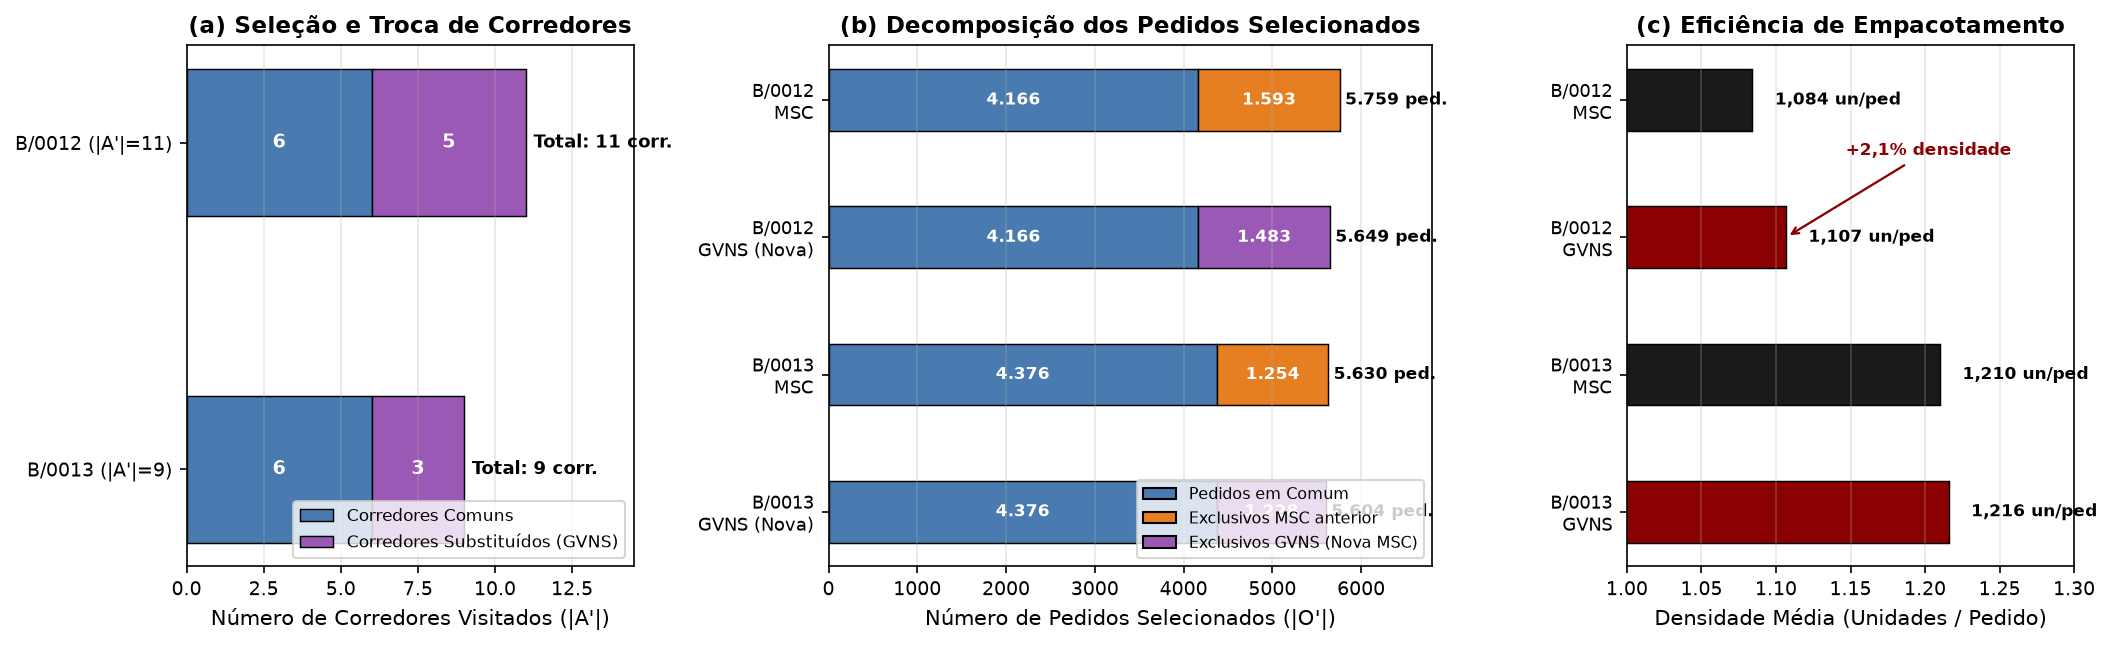

In [4]:
# --- Extração dos dados das soluções reais (MSC vs ILS-VND Nova MSC) ---
def parse_sol_txt(path):
    tokens = [int(x) for x in Path(path).read_text().split()]
    n_o = tokens[0]
    orders = set(tokens[1:n_o+1])
    n_a = tokens[n_o+1]
    aisles = set(tokens[n_o+2:n_o+2+n_a])
    return orders, aisles

msc12_o, msc12_a = parse_sol_txt(BEST_DIR / "instance_0012.txt")
msc13_o, msc13_a = parse_sol_txt(BEST_DIR / "instance_0013.txt")

# Soluções das melhores sementes do ILS-VND
ils_vnd12_json = json.load(open(TEMP_DIR / "b_instance_0012.txt_ils_vnd_li2500_sa600_ps005_21.json"))
ils_vnd13_json = json.load(open(TEMP_DIR / "b_instance_0013.txt_ils_vnd_li2500_sa600_ps005_25.json"))

ils_vnd12_o = set(ils_vnd12_json["selected_orders"])
ils_vnd12_a = set(ils_vnd12_json["visited_aisles"])

ils_vnd13_o = set(ils_vnd13_json["selected_orders"])
ils_vnd13_a = set(ils_vnd13_json["visited_aisles"])

# Métricas estruturais
def get_metrics(msc_o, msc_a, ils_vnd_o, ils_vnd_a, u_msc, u_ils_vnd):
    comum_o = len(msc_o & ils_vnd_o)
    excl_msc_o = len(msc_o - ils_vnd_o)
    excl_ils_vnd_o = len(ils_vnd_o - msc_o)
    
    comum_a = len(msc_a & ils_vnd_a)
    excl_msc_a = len(msc_a - ils_vnd_a)
    excl_ils_vnd_a = len(ils_vnd_a - msc_a)
    
    dens_msc = u_msc / len(msc_o)
    dens_ils_vnd = u_ils_vnd / len(ils_vnd_o)
    
    return {
        "comum_o": comum_o, "excl_msc_o": excl_msc_o, "excl_ils_vnd_o": excl_ils_vnd_o,
        "tot_msc_o": len(msc_o), "tot_ils_vnd_o": len(ils_vnd_o),
        "comum_a": comum_a, "excl_msc_a": excl_msc_a, "excl_ils_vnd_a": excl_ils_vnd_a,
        "tot_a": len(msc_a),
        "dens_msc": dens_msc, "dens_ils_vnd": dens_ils_vnd,
    }

met12 = get_metrics(msc12_o, msc12_a, ils_vnd12_o, ils_vnd12_a, 6244, 6252)
met13 = get_metrics(msc13_o, msc13_a, ils_vnd13_o, ils_vnd13_a, 6813, 6814)

# --- Figura 3: Confronto e Decomposição Estrutural ---
fig, axes = plt.subplots(1, 3, figsize=(14.2, 4.4), gridspec_kw={"width_ratios": [1.0, 1.35, 1.0]})

# (a) Corredores: Comuns vs Substituídos
insts = ["B/0012 (|A'|=11)", "B/0013 (|A'|=9)"]
comuns_a = [met12["comum_a"], met13["comum_a"]]
subst_a = [met12["excl_ils_vnd_a"], met13["excl_ils_vnd_a"]]

y_a = np.arange(len(insts))
b1 = axes[0].barh(y_a, comuns_a, height=0.45, color=COR["Comum"], edgecolor="k", lw=0.7, label="Corredores Comuns")
b2 = axes[0].barh(y_a, subst_a, left=comuns_a, height=0.45, color=COR["Excl_ILS_VND"], edgecolor="k", lw=0.7, label="Corredores Substituídos (ILS-VND)")

for idx_i, (c_a, s_a, tot) in enumerate(zip(comuns_a, subst_a, [11, 9])):
    axes[0].text(c_a / 2, idx_i, f"{c_a}", ha="center", va="center", color="white", fontweight="bold", fontsize=9.0)
    axes[0].text(c_a + s_a / 2, idx_i, f"{s_a}", ha="center", va="center", color="white", fontweight="bold", fontsize=9.0)
    axes[0].text(tot + 0.25, idx_i, f"Total: {tot} corr.", va="center", fontsize=8.5, fontweight="bold")

axes[0].set_yticks(y_a)
axes[0].set_yticklabels(insts, fontsize=9.2)
axes[0].invert_yaxis()
axes[0].set_xlim(0, 14.5)
axes[0].set_xlabel("Número de Corredores Visitados (|A'|)")
axes[0].set_title("(a) Seleção e Troca de Corredores", fontweight="bold")
axes[0].grid(alpha=0.3, axis="x")
axes[0].legend(loc="lower right", fontsize=8.0)

# (b) Decomposição de Pedidos Selecionados: Barras Empilhadas
bar_labels = [
    "B/0012\nMSC", "B/0012\nILS_VND (Nova)",
    "B/0013\nMSC", "B/0013\nILS_VND (Nova)"
]
y_o = np.arange(len(bar_labels))

comuns_plot = [met12["comum_o"], met12["comum_o"], met13["comum_o"], met13["comum_o"]]
excl_plot = [met12["excl_msc_o"], met12["excl_ils_vnd_o"], met13["excl_msc_o"], met13["excl_ils_vnd_o"]]
cores_excl = [COR["Excl_MSC"], COR["Excl_ILS_VND"], COR["Excl_MSC"], COR["Excl_ILS_VND"]]

axes[1].barh(y_o, comuns_plot, height=0.45, color=COR["Comum"], edgecolor="k", lw=0.7, label="Pedidos em Comum (O'_MSC ∩ O'_ILS_VND)")
for idx_o, (c_v, e_v, c_cor) in enumerate(zip(comuns_plot, excl_plot, cores_excl)):
    axes[1].barh(y_o[idx_o], e_v, left=c_v, height=0.45, color=c_cor, edgecolor="k", lw=0.7)
    tot_o = c_v + e_v
    axes[1].text(c_v / 2, idx_o, f"{c_v:,}".replace(",", "."), ha="center", va="center", color="white", fontweight="bold", fontsize=8.2)
    axes[1].text(c_v + e_v / 2, idx_o, f"{e_v:,}".replace(",", "."), ha="center", va="center", color="white", fontweight="bold", fontsize=8.2)
    axes[1].text(tot_o + 60, idx_o, f"{tot_o:,}".replace(",", ".") + " ped.", va="center", fontsize=8.2, fontweight="bold")

axes[1].set_yticks(y_o)
axes[1].set_yticklabels(bar_labels, fontsize=8.8)
axes[1].invert_yaxis()
axes[1].set_xlim(0, 6800)
axes[1].set_xlabel("Número de Pedidos Selecionados (|O'|)")
axes[1].set_title("(b) Decomposição dos Pedidos Selecionados", fontweight="bold")
axes[1].grid(alpha=0.3, axis="x")

# Legenda customizada para o painel b
patch_comum = mpatches.Patch(facecolor=COR["Comum"], edgecolor="k", label="Pedidos em Comum")
patch_msc = mpatches.Patch(facecolor=COR["Excl_MSC"], edgecolor="k", label="Exclusivos MSC anterior")
patch_ils_vnd = mpatches.Patch(facecolor=COR["Excl_ILS_VND"], edgecolor="k", label="Exclusivos ILS-VND (Nova MSC)")
axes[1].legend(handles=[patch_comum, patch_msc, patch_ils_vnd], loc="lower right", fontsize=7.8)

# (c) Densidade Média de Unidades por Pedido
dens_labels = ["B/0012\nMSC", "B/0012\nILS_VND", "B/0013\nMSC", "B/0013\nILS_VND"]
dens_vals = [met12["dens_msc"], met12["dens_ils_vnd"], met13["dens_msc"], met13["dens_ils_vnd"]]
dens_cores = [COR["MSC_Ref"], COR["Nova MSC"], COR["MSC_Ref"], COR["Nova MSC"]]

y_d = np.arange(len(dens_labels))
b_d = axes[2].barh(y_d, dens_vals, height=0.45, color=dens_cores, edgecolor="k", lw=0.7)

for idx_d, d_val in enumerate(dens_vals):
    axes[2].text(d_val + 0.015, idx_d, f"{fmt_num(d_val, 3)} un/ped", va="center", fontsize=8.2, fontweight="bold")

axes[2].set_yticks(y_d)
axes[2].set_yticklabels(dens_labels, fontsize=8.8)
axes[2].invert_yaxis()
axes[2].set_xlim(1.0, 1.30)
axes[2].set_xlabel("Densidade Média (Unidades / Pedido)")
axes[2].set_title("(c) Eficiência de Empacotamento", fontweight="bold")
axes[2].grid(alpha=0.3, axis="x")

# Anotação de ganho percentual de densidade em B/0012
axes[2].annotate(
    "+2,1% densidade",
    xy=(met12["dens_ils_vnd"], 1),
    xytext=(met12["dens_ils_vnd"] + 0.04, 0.4),
    arrowprops=dict(arrowstyle="->", color=COR["Nova MSC"], lw=1.1),
    fontsize=8.0, fontweight="bold", color=COR["Nova MSC"]
)

fig.tight_layout()
salvar_fig(
    fig,
    "novas_msc_decomposicao_estrutural",
    r"Decomposição e confronto estrutural entre a MSC anterior e a Nova MSC descoberta pelo 	exttt{ILS-VND}: (a) número de corredores comuns e substituídos; (b) pedidos selecionados em comum ($\mathcal{O}'_{\mathrm{MSC}} \cap \mathcal{O}'_{\mathrm{ILS-VND}}$) versus exclusivos de cada solução; e (c) densidade média de unidades por pedido, comprovando que o 	exttt{ILS-VND} empacota maior volume útil com menor quantidade de pedidos.",
    "fig:novas_msc_decomposicao_estrutural",
    width=r"0.98	extwidth"
)
plt.show()


## 4. Figura 4: ECDF de Superação e Dispersão Tempo $	imes$ Qualidade das 30 Sementes

Para comprovar a **robustez estocástica** do ILS-VND frente à literatura:
1. **ECDF (Função de Distribuição Cumulativa Empírica)**:
   - Em `B/0012`: $43{,}3\%$ de probabilidade empírica de superar a MSC em uma única execução ($13/30$ sementes com $\Delta > 0$).
   - Em `B/0013`: $100{,}0\%$ de probabilidade empírica de superar a MSC ($30/30$ sementes atingem deterministamente a nova MSC).
2. **Dispersão Tempo $	imes$ Qualidade**:
   - Evidencia que o tempo de execução do ILS-VND é rigorosamente controlado pelo critério de parada temporal ($pprox 593$s $\pm 0{,}5$s), demonstrando que a superação da MSC é fruto da qualidade dos operadores de vizinhança e não de extrapolação do tempo computacional.


[LaTeX salvo] notebooks/resultados/tex/fig_novas_msc_ecdf_tradeoff.tex
[Figura salva] img/novas_msc_ecdf_tradeoff.pdf | img/novas_msc_ecdf_tradeoff.png


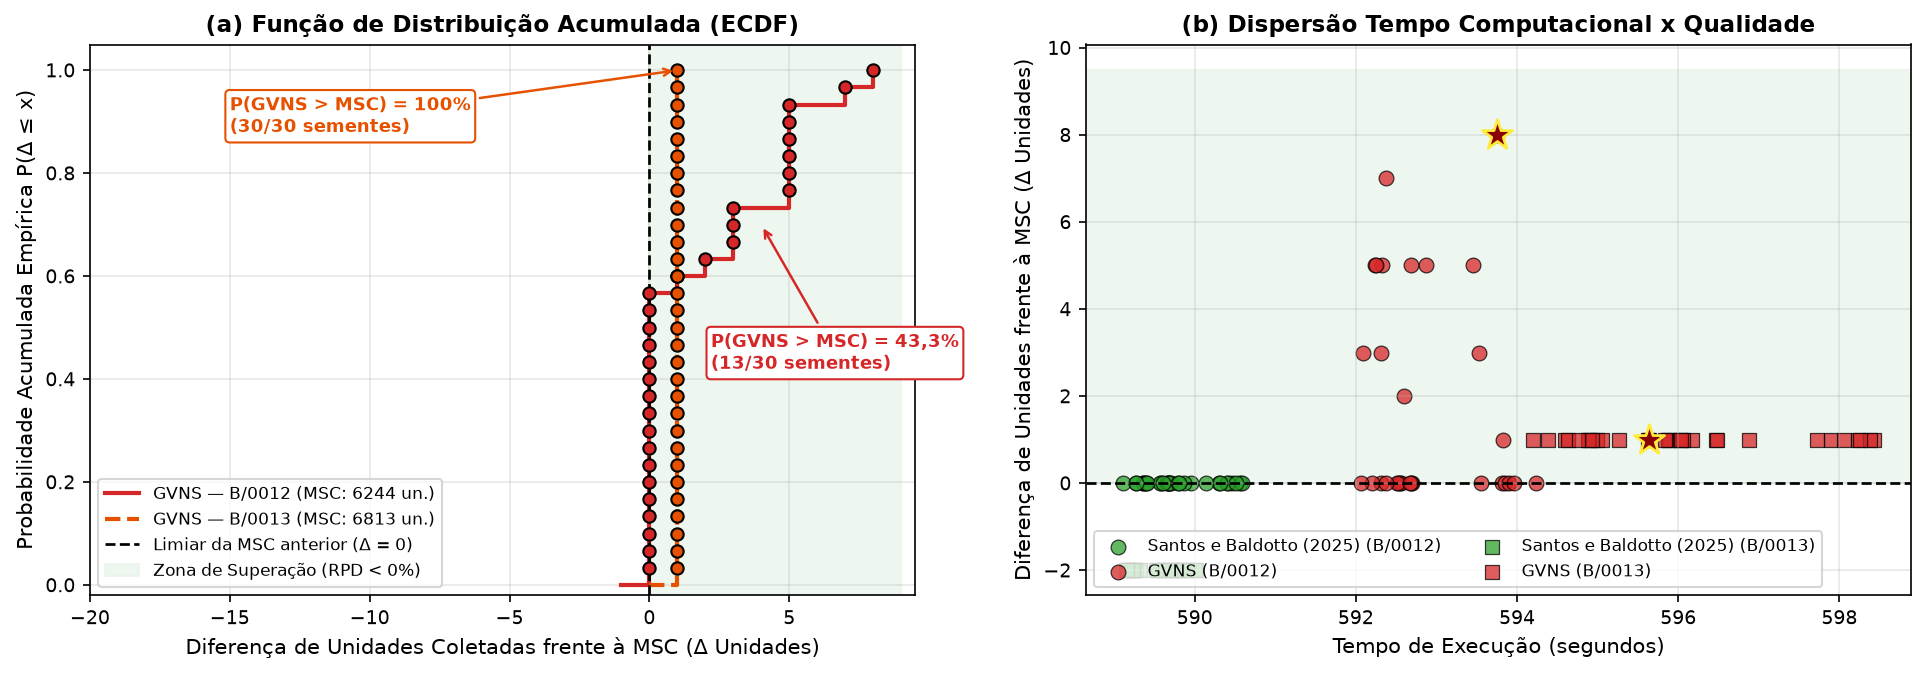

In [5]:
# --- Figura 4: ECDF de Superação e Dispersão Tempo x Qualidade ---
fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.6))

# (a) ECDF do ganho Delta Unidades
for inst_id, ls_style, m_marker in [("instance_0012.txt", "-", "o"), ("instance_0013.txt", "--", "s")]:
    msc_info = MSCS[inst_id]
    sub_ils_vnd = df_runs[(df_runs["instance"] == inst_id) & (df_runs["algo"] == "ILS-VND")]
    deltas = np.sort(sub_ils_vnd["delta_items"].values)
    ecdf = np.arange(1, len(deltas) + 1) / len(deltas)
    
    # Adiciona ponto base para desenhar o degrau completo
    d_step = np.concatenate([[deltas[0] - 1.0], deltas])
    e_step = np.concatenate([[0.0], ecdf])
    
    lbl = f"ILS-VND — {msc_info['label']} (MSC: {int(msc_info['items'])} un.)"
    axes[0].step(d_step, e_step, where="post", color=COR["ILS-VND"] if inst_id == "instance_0012.txt" else "#e65100", lw=2.0, ls=ls_style, label=lbl)
    axes[0].scatter(deltas, ecdf, color=COR["ILS-VND"] if inst_id == "instance_0012.txt" else "#e65100", edgecolor="k", s=35, zorder=3)

# Referência de Santos e Baldotto
axes[0].axvline(0.0, color="k", lw=1.3, ls="--", zorder=2, label="Limiar da MSC anterior (Δ = 0)")
axes[0].axvspan(0.0, 9.0, color=COR["Zona"], alpha=0.7, zorder=0, label="Zona de Superação (RPD < 0%)")

# Anotações de probabilidade de superação
axes[0].annotate(
    "P(ILS-VND > MSC) = 43,3%\n(13/30 sementes)",
    xy=(4.0, 0.70),
    xytext=(2.2, 0.42),
    arrowprops=dict(arrowstyle="->", color=COR["ILS-VND"], lw=1.2),
    fontsize=8.5, fontweight="bold", color=COR["ILS-VND"],
    bbox=dict(boxstyle="round,pad=0.25", facecolor="#ffffff", edgecolor=COR["ILS-VND"])
)

axes[0].annotate(
    "P(ILS-VND > MSC) = 100%\n(30/30 sementes)",
    xy=(1.0, 1.0),
    xytext=(-15.0, 0.88),
    arrowprops=dict(arrowstyle="->", color="#e65100", lw=1.2),
    fontsize=8.5, fontweight="bold", color="#e65100",
    bbox=dict(boxstyle="round,pad=0.25", facecolor="#ffffff", edgecolor="#e65100")
)

axes[0].set_xlim(-20, 9.5)
axes[0].set_ylim(-0.02, 1.05)
axes[0].set_xlabel("Diferença de Unidades Coletadas frente à MSC (Δ Unidades)")
axes[0].set_ylabel("Probabilidade Acumulada Empírica P(Δ ≤ x)")
axes[0].set_title("(a) Função de Distribuição Acumulada (ECDF)", fontweight="bold")
axes[0].grid(alpha=0.3)
axes[0].legend(loc="lower left", fontsize=8.2)

# (b) Dispersão Tempo de Execução x Qualidade
for inst_id, m_symbol in [("instance_0012.txt", "o"), ("instance_0013.txt", "s")]:
    msc_info = MSCS[inst_id]
    sub_inst = df_runs[df_runs["instance"] == inst_id]
    
    for algo in ["Santos e Baldotto (2025)", "ILS-VND"]:
        sub_a = sub_inst[sub_inst["algo"] == algo]
        axes[1].scatter(
            sub_a["exec_time"],
            sub_a["delta_items"],
            color=COR[algo],
            marker=m_symbol,
            s=50,
            alpha=0.75,
            edgecolor="k",
            lw=0.6,
            label=f"{algo} ({msc_info['label']})"
        )

# Destaque das melhores sementes no gráfico de dispersão
for inst_id, m_symbol in [("instance_0012.txt", "o"), ("instance_0013.txt", "s")]:
    sub_ils_vnd = df_runs[(df_runs["instance"] == inst_id) & (df_runs["algo"] == "ILS-VND")]
    best_row = sub_ils_vnd.sort_values(by="items", ascending=False).iloc[0]
    axes[1].scatter(
        best_row["exec_time"],
        best_row["delta_items"],
        marker="*",
        s=230,
        color=COR["Nova MSC"],
        edgecolor="#ffeb3b",
        lw=1.3,
        zorder=5
    )

axes[1].axhline(0.0, color="k", lw=1.3, ls="--", zorder=2)
axes[1].axhspan(0.0, 9.5, color=COR["Zona"], alpha=0.7, zorder=0)

axes[1].set_xlabel("Tempo de Execução (segundos)")
axes[1].set_ylabel("Diferença de Unidades frente à MSC (Δ Unidades)")
axes[1].set_title("(b) Dispersão Tempo Computacional x Qualidade", fontweight="bold")
axes[1].grid(alpha=0.3)
axes[1].legend(loc="lower left", fontsize=8.0, ncol=2)

fig.tight_layout()
salvar_fig(
    fig,
    "novas_msc_ecdf_tradeoff",
    r"Análise estocástica e esforço computacional nas instâncias com nova MSC: (a) Função de Distribuição Acumulada Empírica (ECDF) de $\Delta$ unidades, evidenciando $P(\Delta > 0) = 43{,}3\%$ em 	exttt{B/0012} e $100\%$ em 	exttt{B/0013}; e (b) dispersão entre tempo computacional e qualidade, comprovando o cumprimento uniforme do orçamento de tempo (10 min) e ausência de degradação.",
    "fig:novas_msc_ecdf_tradeoff",
    width=r"0.98	extwidth"
)
plt.show()


## 5. Tabela Resumo Consolidada para o TCC

A tabela abaixo consolida todas as métricas das instâncias **`B/0012`** e **`B/0013`** para inclusão direta no texto ou apêndice do TCC, sendo exportada automaticamente para `notebooks/resultados/tex/tabela_novas_msc_detalhada.tex`.


In [6]:
# --- Tabela Consolidada de B/0012 e B/0013 ---
resumo_rows = []

for inst_id in ["instance_0012.txt", "instance_0013.txt"]:
    msc_info = MSCS[inst_id]
    msc_u = msc_info["items"]
    msc_a = msc_info["aisles"]
    msc_f = msc_info["obj"]
    
    sub = df_runs[df_runs["instance"] == inst_id]
    
    for algo in ["OrderBased", "AisleBased", "ILS-VND", "Santos e Baldotto (2025)"]:
        sub_a = sub[sub["algo"] == algo]
        u_mean = sub_a["items"].mean()
        u_max = sub_a["items"].max()
        f_mean = sub_a["objective"].mean()
        f_max = sub_a["objective"].max()
        rpd_mean = sub_a["rpd"].mean()
        rpd_min = sub_a["rpd"].min()
        t_mean = sub_a["exec_time"].mean()
        a_val = sub_a["aisles"].iloc[0]
        n_sup = (sub_a["items"] > msc_u).sum()
        
        resumo_rows.append({
            "Instância": msc_info["label"],
            "MSC (f*)": f"{fmt_num(msc_f, 2)} ({int(msc_u)}/{msc_a})",
            "Algoritmo": algo,
            "Aisles": a_val,
            "Unidades (Média)": fmt_num(u_mean, 1),
            "Unidades (Máx)": int(u_max),
            "f (Média)": fmt_num(f_mean, 2),
            "f (Melhor)": fmt_num(f_max, 2),
            "RPD Média (%)": fmt_num(rpd_mean, 3, sinal=True),
            "RPD Mín (%)": fmt_num(rpd_min, 3, sinal=True),
            "> MSC": f"{n_sup}/30 ({fmt_num(n_sup/30*100, 1)}%)",
            "Tempo (s)": fmt_num(t_mean, 1),
        })

df_tcc = pd.DataFrame(resumo_rows)
display(df_tcc)

# Exportação para LaTeX
linhas_tex = [
    r"\begin{table}[htbp]",
    r"  \centering",
    r"  \caption{Métricas detalhadas das instâncias \texttt{B/0012} e \texttt{B/0013} com superação de Melhores Soluções Conhecidas (MSCs), comparando médias e valores extremos sobre 30 sementes.}",
    r"  \label{tab:novas_msc_detalhada}",
    r"  \footnotesize",
    r"  \begin{tabular}{llrrrrrrrr}",
    r"    \toprule",
    r"    \textbf{Instância} & \textbf{Algoritmo} & \textbf{$|\mathcal{A}'|$} & \textbf{Unid. Méd.} & \textbf{Unid. Máx.} & \textbf{$f$ Méd.} & \textbf{$f$ Máx.} & \textbf{RPD Méd.} & \textbf{RPD Mín.} & \textbf{Tempo (s)} \\",
    r"    \midrule",
]

for inst_nome in ["B/0012", "B/0013"]:
    sub_tab = df_tcc[df_tcc["Instância"] == inst_nome]
    msc_str = sub_tab["MSC (f*)"].iloc[0]
    linhas_tex.append(rf"    \multicolumn{{10}}{{l}}{{\textbf{{{inst_nome}}} --- MSC anterior: $f^* = {msc_str}$}} \\")
    linhas_tex.append(r"    \midrule")
    for _, row in sub_tab.iterrows():
        is_ils_vnd = row["Algoritmo"] == "ILS-VND"
        pref = r"    \textbf{" if is_ils_vnd else "    "
        suf = "}" if is_ils_vnd else ""
        linhas_tex.append(
            f"{pref}{row['Instância']}{suf} & "
            f"{pref}{row['Algoritmo']}{suf} & "
            f"{row['Aisles']} & "
            f"{row['Unidades (Média)']} & "
            f"{row['Unidades (Máx)']} & "
            f"{row['f (Média)']} & "
            f"{pref}{row['f (Melhor)']}{suf} & "
            f"{pref}{row['RPD Média (%)']}{suf} & "
            f"{pref}{row['RPD Mín (%)']}{suf} & "
            f"{row['Tempo (s)']} \\"
        )
    linhas_tex.append(r"    \midrule")

linhas_tex.extend([
    r"    \bottomrule",
    r"  \end{tabular}",
    r"  \caption*{\footnotesize Fonte: Elaborado pelo autor, 2026.}",
    r"\end{table}",
])

salvar_tex("tabela_novas_msc_detalhada", linhas_tex)
print("Notebook executado e tabelas LaTeX geradas com sucesso!")


,Instância,MSC (f*),Algoritmo,Aisles,Unidades (Média),Unidades (Máx),f (Média),f (Melhor),RPD Média (%),RPD Mín (%),> MSC,Tempo (s)
0,B/0012,"567,64 (6244/11)",OrderBased,452,"12808,0",12808,"28,34","28,34","+95,008","+95,008","30/30 (100,0%)","32,5"
1,B/0012,"567,64 (6244/11)",AisleBased,11,"6244,0",6244,"567,64","567,64","+0,000","+0,000","0/30 (0,0%)","3,7"
2,B/0012,"567,64 (6244/11)",GVNS,11,"6245,9",6252,"567,81","568,36","-0,030","-0,128","13/30 (43,3%)","592,9"
3,B/0012,"567,64 (6244/11)",Santos e Baldotto (2025),11,"6244,0",6244,"567,64","567,64","+0,000","+0,000","0/30 (0,0%)","589,8"
4,B/0013,"757,00 (6813/9)",OrderBased,466,"19417,0",19417,"41,67","41,67","+94,496","+94,496","30/30 (100,0%)","3,4"
5,B/0013,"757,00 (6813/9)",AisleBased,9,"6761,0",6761,"751,22","751,22","+0,763","+0,763","0/30 (0,0%)","7,9"
6,B/0013,"757,00 (6813/9)",GVNS,9,"6814,0",6814,"757,11","757,11","-0,015","-0,015","30/30 (100,0%)","596,1"
7,B/0013,"757,00 (6813/9)",Santos e Baldotto (2025),9,"6811,0",6811,"756,78","756,78","+0,029","+0,029","0/30 (0,0%)","589,6"


[LaTeX salvo] notebooks/resultados/tex/tabela_novas_msc_detalhada.tex
Notebook executado e tabelas LaTeX geradas com sucesso!


## 5. Figura `pedidos_corredores_objetivo` — Unidades Coletadas, Corredores Visitados e Função Objetivo (`B/0012` e `B/0013`)

**Correções aplicadas conforme revisão**:
1. **Terminologia exata**: A coluna `items` representa **unidades coletadas** ($\lvert\mathcal{O}'\rvert$, numerador de $f = \text{Unidades}/\text{Corredores}$), corrigindo os rótulos dos eixos, legenda, título e *caption* LaTeX.
2. **Ordem padronizada dos algoritmos**: `OrderBased`, `AisleBased`, `ILS-VND` e `Santos e Baldotto (2025)`, mantendo a mesma sequência de todas as tabelas e figuras do TCC.
3. **Precisão aritmética na instância `B/0012`**: O `ILS-VND` coleta em média $6.245{,}9$ unidades em $11$ corredores ($6.245{,}9 / 11 = 567{,}81$), diferenciando-se explicitamente das $6.244$ unidades ($f = 567{,}64$) de `AisleBased` e `Santos e Baldotto (2025)`.

[LaTeX salvo] notebooks/resultados/tex/fig_pedidos_corredores_objetivo.tex
[Figura salva] img/pedidos_corredores_objetivo.pdf | img/pedidos_corredores_objetivo.png


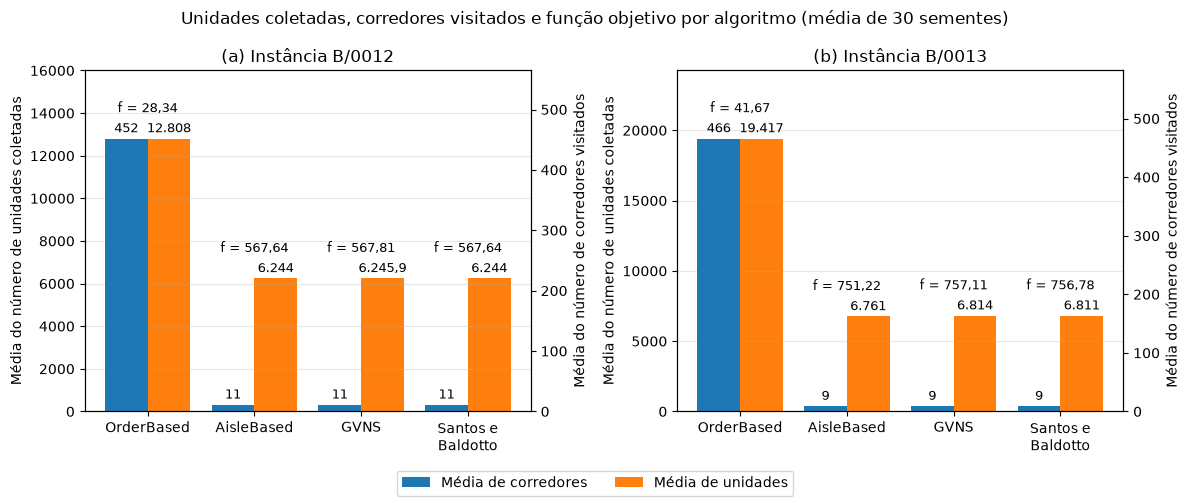

In [7]:
# --- Figura 5: Gráfico de Barras — Unidades Coletadas, Corredores Visitados e Função Objetivo ---
ALGOS_ORDEM = ["OrderBased", "AisleBased", "ILS-VND", "Santos e Baldotto (2025)"]
ROTULOS_X = ["OrderBased", "AisleBased", "ILS-VND", "Santos e\nBaldotto"]

def fmt_milhar(v, casas=0):
    if casas <= 0 or abs(v - round(v)) < 1e-6:
        return f"{int(round(v)):,}".replace(",", ".")
    int_p = int(v)
    dec_p = int(round((v - int_p) * (10 ** casas)))
    return f"{int_p:,}".replace(",", ".") + f",{dec_p:0{casas}d}"

with plt.style.context("default"):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    for idx_p, inst_id in enumerate(["instance_0012.txt", "instance_0013.txt"]):
        ax = axes[idx_p]
        msc_info = MSCS[inst_id]
        sub = df_runs[df_runs["instance"] == inst_id]

        x = np.arange(len(ALGOS_ORDEM))
        width = 0.4

        unidades = [sub[sub["algo"] == a]["items"].mean() for a in ALGOS_ORDEM]
        corredores = [sub[sub["algo"] == a]["aisles"].mean() for a in ALGOS_ORDEM]
        objetivos = [sub[sub["algo"] == a]["objective"].mean() for a in ALGOS_ORDEM]

        # Eixo Y principal (esquerda): unidades | Eixo Y secundário (direita): corredores
        ax_corr = ax.twinx()
        bars_corr = ax_corr.bar(x - width / 2, corredores, width, color="C0", label="Média de corredores")
        bars_unid = ax.bar(x + width / 2, unidades, width, color="C1", label="Média de unidades")

        max_u, max_c = max(unidades), max(corredores)
        ax.set_ylim(0, max_u * 1.25)
        ax_corr.set_ylim(0, max_c * 1.25)

        # Valores sobre cada coluna
        for bar, c_val in zip(bars_corr, corredores):
            ax_corr.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + max_c * 0.012,
                fmt_milhar(c_val, 0),
                ha="center", va="bottom", fontsize=9,
            )
        for bar, u_val in zip(bars_unid, unidades):
            casas_u = 1 if abs(u_val - round(u_val)) > 1e-4 else 0
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + max_u * 0.012,
                fmt_milhar(u_val, casas_u),
                ha="center", va="bottom", fontsize=9,
            )

        # Valor da função objetivo acima de cada par de colunas
        for i in range(len(ALGOS_ORDEM)):
            topo = max(unidades[i] / max_u, corredores[i] / max_c) * max_u
            ax.text(
                x[i],
                topo + max_u * 0.085,
                f"f = {fmt_num(objetivos[i], 2)}",
                ha="center", va="bottom", fontsize=9.5,
            )

        ax.set_xticks(x)
        ax.set_xticklabels(ROTULOS_X)
        ax.set_ylabel("Média do número de unidades coletadas")
        ax_corr.set_ylabel("Média do número de corredores visitados")
        ax.set_title(f"({chr(97 + idx_p)}) Instância {msc_info['label']}")
        ax.grid(alpha=0.3, axis="y")

    fig.suptitle("Unidades coletadas, corredores visitados e função objetivo por algoritmo (média de 30 sementes)")

    handles = [bars_corr, bars_unid]
    fig.legend(
        handles=handles,
        labels=["Média de corredores", "Média de unidades"],
        loc="lower center",
        ncol=2,
    )
    fig.tight_layout(rect=(0, 0.06, 1, 1))

    salvar_fig(
        fig,
        "pedidos_corredores_objetivo",
        r"Unidades coletadas, corredores visitados e valor da função objetivo ($f = \text{Unidades}/\text{Corredores}$) por algoritmo nas instâncias \texttt{B/0012} e \texttt{B/0013} (média de 30 sementes). Acima de cada par de colunas é indicado o valor médio de $f$.",
        "fig:pedidos_corredores_objetivo",
        width=r"0.98\textwidth",
    )
    plt.show()